<a id="chapter-01"></a>

# Chapter 01 · What Is Reinforcement Learning? / 什么是强化学习

[← 学习索引](README.md) · [项目主页](../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 分清监督学习与强化学习
- 识别 agent、environment、state、action、reward
- 读懂 MDP、策略与回报

**开始前最好已经会：**

- 会读简单求和符号 $\\sum$
- 知道概率和期望的直观含义
- 会运行 Python/NumPy 单元格


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Supervised / unsupervised / reinforcement learning | 问题引入与心智模型 | 对比理解 |
| Complications in RL | 常见坑与扩展 | 延迟奖励、非平稳、探索 |
| RL formalisms: reward, agent, environment, action, observation | 符号表与交互递归 | 详细 |
| Markov process / MRP / MDP | 分步推导、矩阵求值实验 | 详细 |
| Policy | 价值定义与后续章节连接 | 主线 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

如果今天拿到 1 分，或者等两步后拿到 10 分，智能体应怎样比较？强化学习的全部困难，几乎都从“动作会改变未来”这件事开始。

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

智能体观察 $S_t$，按策略 $\pi(a|s)$ 选出 $A_t$；环境返回 $R_{t+1}$ 与 $S_{t+1}$。学习目标不是眼前奖励，而是长期累计回报。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $S_t$ | 时刻 $t$ 的状态 | 作决定时已有的信息 |
| $A_t$ | 智能体采取的动作 | 由策略选择 |
| $R_{t+1}$ | 执行动作后得到的奖励 | 下标提醒它在动作之后到来 |
| $\\pi(a\mid s)$ | 策略 | 在状态 $s$ 选动作 $a$ 的概率 |
| $\\gamma$ | 折扣因子 | 未来奖励的权重，范围通常为 $[0,1)$ |
| $G_t$ | 从时刻 $t$ 开始的回报 | 未来奖励的折扣和 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 从“未来一共能拿多少分”开始

把未来奖励依次写出：

$$G_t=R_{t+1}+\gamma R_{t+2}+\gamma^2R_{t+3}+\cdots$$

把第一项以外的部分提出一个 $\gamma$：

$$G_t=R_{t+1}+\gamma(R_{t+2}+\gamma R_{t+3}+\cdots)$$

括号内恰好是下一时刻的回报 $G_{t+1}$，所以得到最重要的递归式：

$$\boxed{G_t=R_{t+1}+\gamma G_{t+1}}$$

### 2. 从回报到价值

同一状态下，环境和策略都可能有随机性，因此单次 $G_t$ 会波动。对所有可能未来取条件期望：

$$V^\pi(s)=\mathbb E_\pi[G_t\mid S_t=s]$$

把回报递归式代入：

$$V^\pi(s)=\mathbb E_\pi[R_{t+1}+\gamma V^\pi(S_{t+1})\mid S_t=s]$$

这就是 Bellman expectation equation。它不是凭空规定，而是“回报递归 + 条件期望”的直接结果。

### 3. 为什么矩阵解是 $(I-\gamma P)^{-1}r$

对有限 Markov reward process，可写成 $V=r+\gamma PV$。移项得到
$$(I-\gamma P)V=r,$$
若矩阵可逆，就有 $V=(I-\gamma P)^{-1}r$。代码中应使用 `solve`，不要显式计算逆矩阵。


## 4. 手算一个最小例子


奖励序列为 $[1,0,2]$，$\gamma=0.9$。从后向前算：

- $G_2=2$
- $G_1=0+0.9\times2=1.8$
- $G_0=1+0.9\times1.8=2.62$

先手算再运行代码；预期输出应为 `[2.62, 1.8, 2.0]`。这也是倒序循环中 `running = reward + gamma * running` 的来源。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### 核心公式

折扣回报：

$$G_t=R_{t+1}+\gamma R_{t+2}+\gamma^2R_{t+3}+\cdots=\sum_{k=0}^{\infty}\gamma^kR_{t+k+1}$$

状态价值与动作价值：

$$V^\pi(s)=\mathbb E_\pi[G_t\mid S_t=s],\qquad Q^\pi(s,a)=\mathbb E_\pi[G_t\mid S_t=s,A_t=a]$$

其中 $0\le\gamma<1$ 控制“多看重未来”。MDP 用 $(\mathcal S,\mathcal A,P,R,\gamma)$ 描述；Markov 性表示预测未来只需要当前状态，而不需要完整历史。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $R_{t+1}$ | `rewards[i]` | 当前位置的即时奖励 |
| $G_{t+1}$ | 更新前的 `running` | 已经算好的后续回报 |
| $G_t$ | 更新后的 `running` | 当前时刻回报 |
| $P$ | `P`，shape `(n, n)` | 状态转移概率矩阵 |
| $(I-\\gamma P)V=r$ | `np.linalg.solve(I - gamma * P, r)` | 直接解线性方程 |

**从公式过渡到代码时：**下面先把回报公式直接翻译成倒序循环，再解一个两状态 Markov reward process。倒序计算能把复杂度从重复求和降到一次遍历。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [4]:
import numpy as np

def discounted_returns(rewards, gamma=0.9):
    # 返回每个时刻的 G_t；rewards[i] 对应 R_{i+1}。
    returns = np.zeros(len(rewards), dtype=float)
    running = 0.0
    for i in range(len(rewards) - 1, -1, -1):
        running = rewards[i] + gamma * running
        returns[i] = running
    return returns

rewards = [1, 0, 2]
print("G_t:", discounted_returns(rewards, gamma=0.9))

# MRP 的 Bellman 方程 V = r + gamma P V，可整理为线性方程求解。
P = np.array([[0.7, 0.3], [0.2, 0.8]])
r = np.array([1.0, 2.0])
gamma = 0.9
V = np.linalg.solve(np.eye(2) - gamma * P, r)
print("V:", V)


G_t: [2.62 1.8  2.  ]
V: [14.90909091 16.72727273]


### 怎样读运行结果

第一段输出必须与手算一致。第二段的两个价值都大于单步奖励，因为价值包含长期累积奖励。把 $\gamma$ 改小，价值会更接近即时奖励。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
给定策略 π 和环境：
1. 从初始状态 S0 开始。
2. 按 π(·|St) 选择动作 At。
3. 环境产生 Rt+1、St+1。
4. 重复直到终止，得到一条 trajectory。
5. 从后向前计算 Gt = Rt+1 + γGt+1。
6. 多条轨迹中，同一状态的 Gt 平均值就是 Vπ(s) 的 Monte Carlo 估计。
```

已知 MRP 转移矩阵时无需采样，可直接解 $(I-\gamma P)V=r$；未知环境时只能通过轨迹估计。这一分叉会贯穿全书：**model-based 使用模型，model-free 使用样本**。


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [5]:
import numpy as np

# 验证 Bellman 方程的残差：正确解应使 r + gamma P V - V 接近 0。
P = np.array([[0.7, 0.3], [0.2, 0.8]])
r = np.array([1.0, 2.0])
gamma = 0.9
V = np.linalg.solve(np.eye(2) - gamma * P, r)
residual = r + gamma * P @ V - V
print("Bellman residual:", residual)
assert np.allclose(residual, 0.0)


Bellman residual: [0. 0.]


## 10. 项目源码精读路线

本章没有配套源码目录；两个数值实验就是本章的完整可执行部分。

<details>
<summary>为什么按这个顺序读</summary>

本章没有仓库脚本，原因是它负责建立语言而不是训练模型。建议把本章代码当成后续实现的单元测试基准：任何 TD target 最终都应能追溯到 `reward + gamma * future_value`。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**Bellman residual（相邻两次价值估计的最大变化）

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


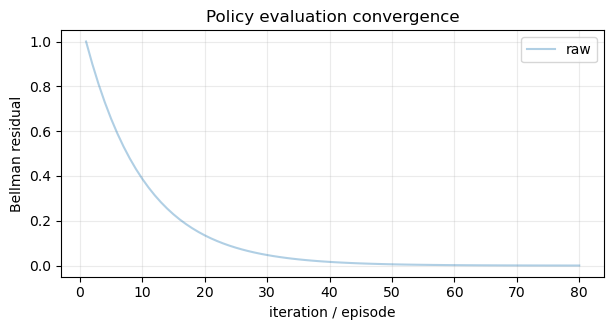

estimated V: [6.692 8.18  9.998] final residual: 2.43e-04


In [6]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


gamma = 0.9
# 固定策略下的 3 状态 MRP；最后一个状态会持续获得奖励 1。
P = np.array([[0.5, 0.5, 0.0], [0.0, 0.5, 0.5], [0.0, 0.0, 1.0]])
r = np.array([0.0, 0.0, 1.0])
v = np.zeros(3)
residuals = []
for _ in range(80):
    new_v = r + gamma * P @ v
    residuals.append(np.max(np.abs(new_v - v)))
    v = new_v

plot_curve(residuals, "Policy evaluation convergence", "Bellman residual")
print("estimated V:", np.round(v, 3), "final residual:", f"{residuals[-1]:.2e}")


### 曲线怎么读

残差应快速下降后逐渐贴近 0；这表示反复 Bellman backup 正在逼近固定点。价值本身上升并不等于发散，要看残差是否收敛。

### 调参过程：一次只改变一个因素

- 先固定 $\gamma=0.9$ 建立基线。
- 把 $\gamma$ 改为 0.5、0.99，只比较收敛速度和价值尺度。
- 设停止条件 `residual < tolerance`，再权衡精度与迭代次数。

### 失败案例复盘

- 只看价值变大就误判发散：高 $\gamma$ 本来就会放大长期价值。
- 原地更新与同步更新混用，导致结果顺序相关。
- 持续任务使用 $\gamma=1$，回报和价值可能没有有限解。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 先确定状态是否真的包含决策所需信息；缺失历史时问题可能是 POMDP。
- 奖励是任务定义，价值是策略下对未来奖励的预测，两者不要混用。
- $\gamma$ 越大不等于一定越好：有效时间跨度大约为 $1/(1-\gamma)$。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

把奖励改为 `[0, 0, 10]`，分别使用 $\gamma=0,0.5,0.99$；解释第一个时刻的回报为何变化。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

对 `[0,0,10]`：$\gamma=0$ 时第一个回报为 0；$\gamma=0.5$ 时为 2.5；$\gamma=0.99$ 时为 9.801。折扣越接近 1，越重视远期奖励。注意这不意味着总应选择大 $\gamma$：持续任务的方差和有效时间跨度也会变大。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- RL 的核心对象是长期回报，不是单步奖励。
- $G_t=R_{t+1}+\gamma G_{t+1}$ 是后续 Bellman、TD、DQN、actor-critic 的共同起点。
- 价值是随机未来回报的条件期望。
- 状态必须包含预测未来所需的信息，才满足 Markov 性。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**不看上文：为什么回报要倒序计算？奖励和价值的区别是什么？

<details>
<summary>展开答案</summary>

因为 $G_t$ 依赖已经知道的 $G_{t+1}$，倒序一次遍历即可。奖励是环境某一步给出的反馈；价值是某策略下从当前状态出发的未来累计奖励期望。
</details>


## 17. 与前后章节连接

第 2 章把这里抽象的 agent/environment 交互落成 Gymnasium API；第 5 章会把回报递归正式变成 Bellman 最优方程。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

持续任务常用平均奖励或 differential return；观测不满足 Markov 性时，可堆叠历史、使用 RNN，或显式建模 belief state。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-01) · [← 学习索引](README.md)
